In [1]:
import sys
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
import yfinance as yf

print("Python executable:", sys.executable)
print("Quant research environment ready!")

ModuleNotFoundError: No module named 'numpy'

In [ ]:

from pathlib import Path
import pandas as pd

# Load the fixed historical dataset
data_path = Path("apple_stock_data.csv")

if not data_path.exists():
    raise FileNotFoundError(
        "Dataset not found. Run this notebook from "
        "the Project1_Probability_Distributions folder."
    )

df = pd.read_csv(
    data_path,
    index_col="Date",
    parse_dates=True
)

# Verify successful loading
print(f"Loaded {len(df)} price observations.")
print(df.head())


ModuleNotFoundError: No module named 'pandas'

In [ ]:
# Check the first few rows
print(df.head())

                                Open       High        Low      Close  \
Date                                                                    
2019-09-16 00:00:00-04:00  52.234325  53.680947  52.171952  52.234325   
2019-09-23 00:00:00-04:00  52.527012  53.376274  52.092786  52.495827   
2019-09-30 00:00:00-04:00  52.994825  54.750926  51.610581  54.460640   
2019-10-07 00:00:00-04:00  54.283122  57.010832  53.817707  56.667770   
2019-10-14 00:00:00-04:00  56.353479  57.128372  55.945643  56.715736   

                              Volume  Dividends  Stock Splits  
Date                                                           
2019-09-16 00:00:00-04:00  569162000        0.0           0.0  
2019-09-23 00:00:00-04:00  465780800        0.0           0.0  
2019-09-30 00:00:00-04:00  634486800        0.0           0.0  
2019-10-07 00:00:00-04:00  588705600        0.0           0.0  
2019-10-14 00:00:00-04:00  422709600        0.0           0.0  


In [ ]:
# Check for basic info (data types, non-null counts)
print(df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 261 entries, 2019-09-16 00:00:00-04:00 to 2024-09-09 00:00:00-04:00
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Open          261 non-null    float64
 1   High          261 non-null    float64
 2   Low           261 non-null    float64
 3   Close         261 non-null    float64
 4   Volume        261 non-null    int64  
 5   Dividends     261 non-null    float64
 6   Stock Splits  261 non-null    float64
dtypes: float64(6), int64(1)
memory usage: 16.3+ KB
None


In [ ]:
# Check for missing values
print(df.isnull().sum())

Open            0
High            0
Low             0
Close           0
Volume          0
Dividends       0
Stock Splits    0
dtype: int64


In [ ]:
# Check for duplicates
print(df.duplicated().sum())

0


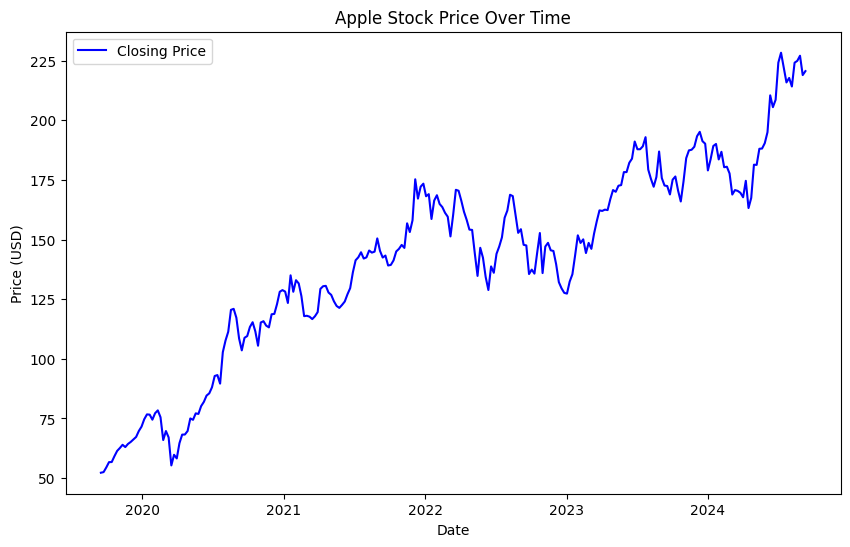

In [ ]:
import matplotlib.pyplot as plt
# Plot the stock's closing prices
plt.figure(figsize=(10,6))
plt.plot(df['Close'], label = 'Closing Price', color = 'blue')
plt.title('Apple Stock Price Over Time')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.show()

In [ ]:


import numpy as np

# Calculate continuously compounded weekly returns
weekly_log_returns = np.log(
    df["Close"] / df["Close"].shift(1)
).dropna()

# Verify the observations
print("Number of price observations:", len(df))
print("Number of weekly returns:", len(weekly_log_returns))
print("Missing returns:", weekly_log_returns.isna().sum())

# Display the first five returns
print("\nFirst five weekly returns:")
print(weekly_log_returns.head())



Number of price observations: 261
Number of weekly returns: 260
Missing returns: 0

First five weekly returns:
Date
2019-09-23 00:00:00-04:00    0.004994
2019-09-30 00:00:00-04:00    0.036745
2019-10-07 00:00:00-04:00    0.039727
2019-10-14 00:00:00-04:00    0.000846
2019-10-21 00:00:00-04:00    0.042119
Name: Close, dtype: float64


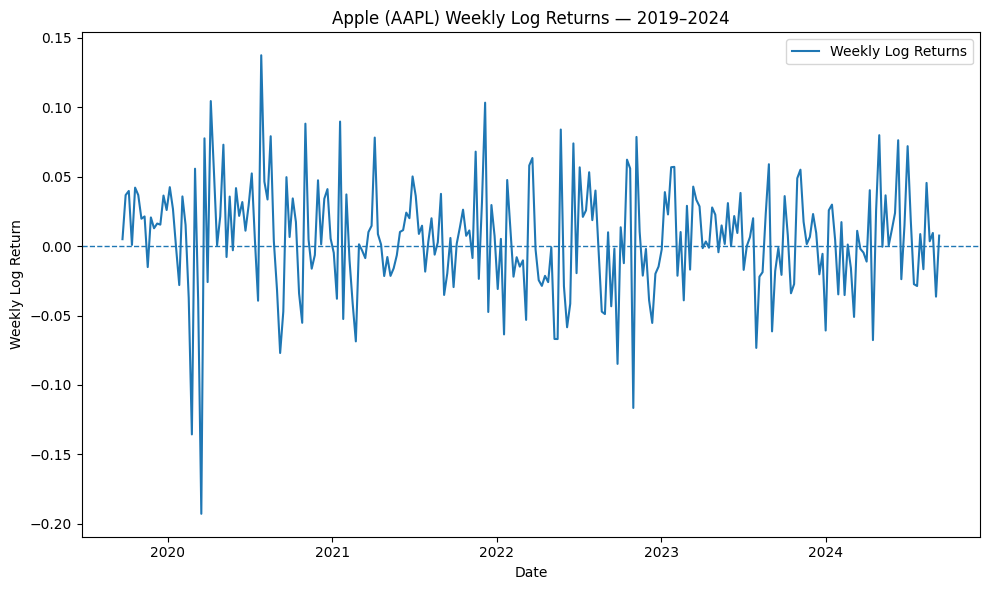

In [ ]:

import matplotlib.pyplot as plt

# Visualise weekly log returns
plt.figure(figsize=(10, 6))

plt.plot(
    weekly_log_returns.index,
    weekly_log_returns.values,
    label="Weekly Log Returns"
)

plt.title("Apple (AAPL) Weekly Log Returns — 2019–2024")
plt.xlabel("Date")
plt.ylabel("Weekly Log Return")
plt.axhline(y=0, linestyle="--", linewidth=1)
plt.legend()
plt.tight_layout()
plt.show()


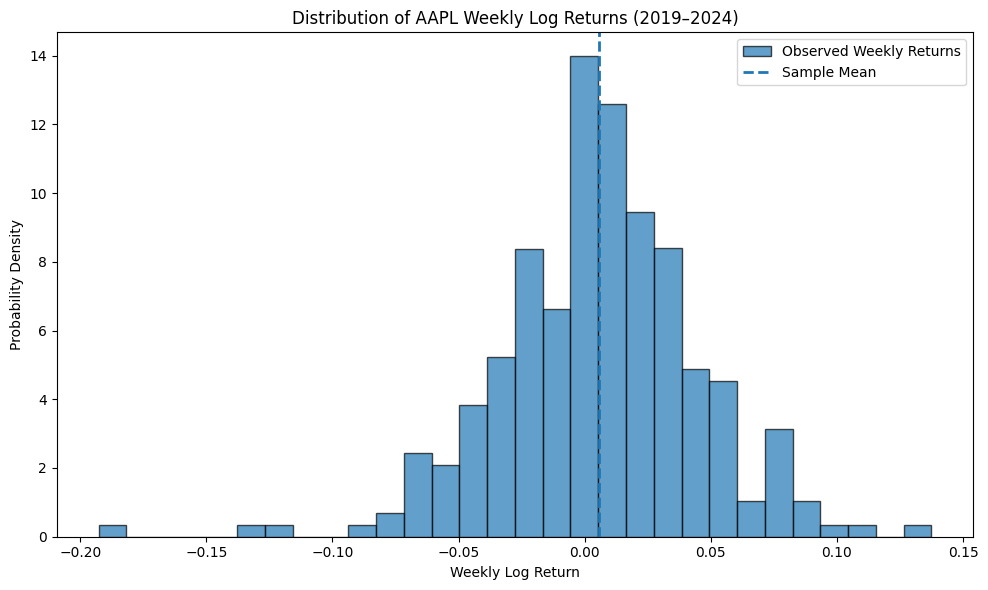

In [ ]:

import matplotlib.pyplot as plt

# Plot the empirical distribution of weekly returns
plt.figure(figsize=(10, 6))

plt.hist(
    weekly_log_returns,
    bins=30,
    density=True,
    alpha=0.7,
    edgecolor="black",
    label="Observed Weekly Returns"
)

plt.axvline(
    weekly_log_returns.mean(),
    linestyle="--",
    linewidth=2,
    label="Sample Mean"
)

plt.title("Distribution of AAPL Weekly Log Returns (2019–2024)")
plt.xlabel("Weekly Log Return")
plt.ylabel("Probability Density")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:

from scipy.stats import skew, kurtosis

# Calculate descriptive statistics
mean_return = weekly_log_returns.mean()
variance_return = weekly_log_returns.var()
std_return = weekly_log_returns.std()

skewness_return = skew(
    weekly_log_returns,
    bias=False
)

excess_kurtosis = kurtosis(
    weekly_log_returns,
    fisher=True,
    bias=False
)

print(f"Mean weekly log return: {mean_return:.6f}")
print(f"Variance: {variance_return:.6f}")
print(f"Standard deviation: {std_return:.6f}")
print(f"Skewness: {skewness_return:.4f}")
print(f"Excess kurtosis: {excess_kurtosis:.4f}")


Mean weekly log return: 0.005542
Variance: 0.001612
Standard deviation: 0.040144
Skewness: -0.4817
Excess kurtosis: 2.5951


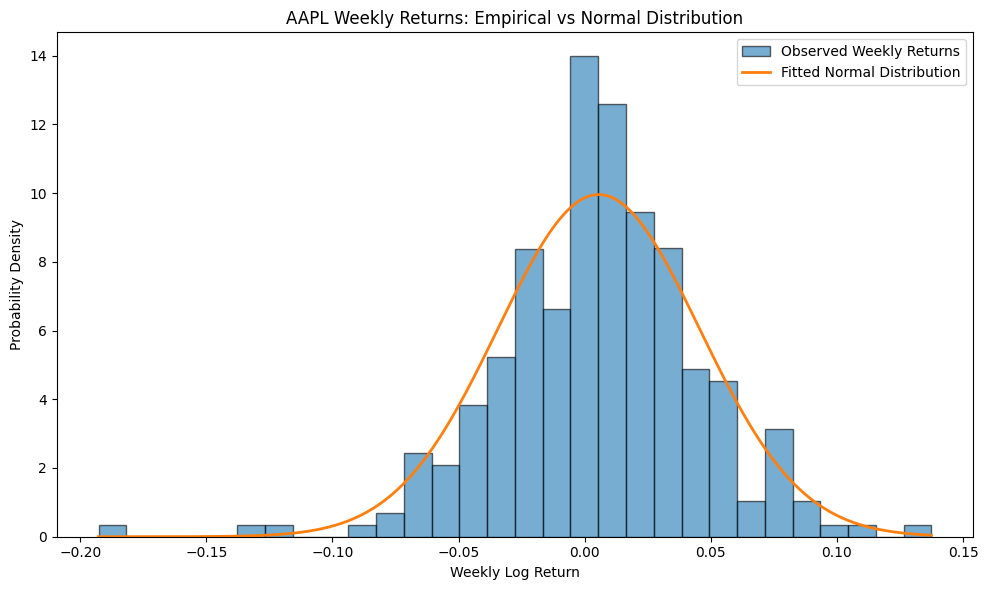

Fitted mean: 0.005542
Fitted standard deviation: 0.040067


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Estimate normal distribution parameters
mu, sigma = norm.fit(weekly_log_returns)

# Generate values for the fitted probability density
x = np.linspace(
    weekly_log_returns.min(),
    weekly_log_returns.max(),
    500
)

normal_pdf = norm.pdf(x, loc=mu, scale=sigma)

# Compare observed returns with fitted normal distribution
plt.figure(figsize=(10, 6))

plt.hist(
    weekly_log_returns,
    bins=30,
    density=True,
    alpha=0.6,
    edgecolor="black",
    label="Observed Weekly Returns"
)

plt.plot(
    x,
    normal_pdf,
    linewidth=2,
    label="Fitted Normal Distribution"
)

plt.title("AAPL Weekly Returns: Empirical vs Normal Distribution")
plt.xlabel("Weekly Log Return")
plt.ylabel("Probability Density")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Fitted mean: {mu:.6f}")
print(f"Fitted standard deviation: {sigma:.6f}")


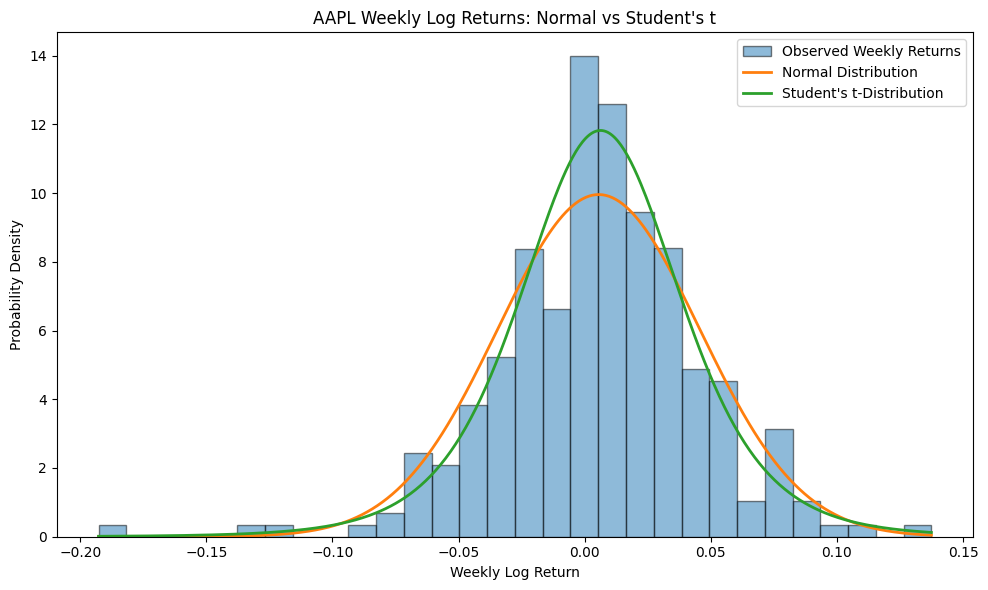

Degrees of freedom: 5.7041
Location: 0.006262
Scale: 0.032306


In [ ]:

from scipy.stats import t

# Fit Student's t-distribution to weekly log returns
df_t, loc_t, scale_t = t.fit(weekly_log_returns)

# Calculate its probability density
t_pdf = t.pdf(
    x,
    df=df_t,
    loc=loc_t,
    scale=scale_t
)

# Compare both fitted distributions
plt.figure(figsize=(10, 6))

plt.hist(
    weekly_log_returns,
    bins=30,
    density=True,
    alpha=0.5,
    edgecolor="black",
    label="Observed Weekly Returns"
)

plt.plot(
    x,
    normal_pdf,
    linewidth=2,
    label="Normal Distribution"
)

plt.plot(
    x,
    t_pdf,
    linewidth=2,
    label="Student's t-Distribution"
)

plt.title("AAPL Weekly Log Returns: Normal vs Student's t")
plt.xlabel("Weekly Log Return")
plt.ylabel("Probability Density")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Degrees of freedom: {df_t:.4f}")
print(f"Location: {loc_t:.6f}")
print(f"Scale: {scale_t:.6f}")


In [ ]:

from scipy.stats import norm, t
import numpy as np

# Number of observed weekly returns
n = len(weekly_log_returns)

# Calculate log-likelihood for each fitted model
ll_normal = np.sum(
    norm.logpdf(weekly_log_returns, loc=mu, scale=sigma)
)

ll_t = np.sum(
    t.logpdf(
        weekly_log_returns,
        df=df_t,
        loc=loc_t,
        scale=scale_t
    )
)

# Number of estimated model parameters
k_normal = 2
k_t = 3

# Calculate Akaike Information Criterion
aic_normal = 2 * k_normal - 2 * ll_normal
aic_t = 2 * k_t - 2 * ll_t

# Calculate Bayesian Information Criterion
bic_normal = k_normal * np.log(n) - 2 * ll_normal
bic_t = k_t * np.log(n) - 2 * ll_t

print(f"Normal AIC: {aic_normal:.4f}")
print(f"Student's t AIC: {aic_t:.4f}")
print(f"Normal BIC: {bic_normal:.4f}")
print(f"Student's t BIC: {bic_t:.4f}")

print("\nPreferred model by AIC:",
      "Student's t" if aic_t < aic_normal else "Normal")

print("Preferred model by BIC:",
      "Student's t" if bic_t < bic_normal else "Normal")


Normal AIC: -931.0965
Student's t AIC: -946.3899
Normal BIC: -923.9752
Student's t BIC: -935.7079

Preferred model by AIC: Student's t
Preferred model by BIC: Student's t


In [ ]:

import numpy as np
from scipy.stats import norm, t

# 1. Split historical returns chronologically
split_index = int(len(weekly_log_returns) * 0.8)

train_returns = weekly_log_returns.iloc[:split_index]
test_returns = weekly_log_returns.iloc[split_index:]

# 2. Fit distributions using TRAINING data only
train_mu, train_sigma = norm.fit(train_returns)

train_df_t, train_loc_t, train_scale_t = t.fit(
    train_returns
)

# 3. Evaluate the fitted models on unseen TEST data
normal_test_ll = np.sum(
    norm.logpdf(
        test_returns,
        loc=train_mu,
        scale=train_sigma
    )
)

t_test_ll = np.sum(
    t.logpdf(
        test_returns,
        df=train_df_t,
        loc=train_loc_t,
        scale=train_scale_t
    )
)

# 4. Report results
print(f"Training observations: {len(train_returns)}")
print(f"Testing observations: {len(test_returns)}")

print(f"\nNormal test log-likelihood: {normal_test_ll:.4f}")
print(f"Student's t test log-likelihood: {t_test_ll:.4f}")

print(
    "\nPreferred out-of-sample model:",
    "Student's t" if t_test_ll > normal_test_ll else "Normal"
)


Training observations: 208
Testing observations: 52

Normal test log-likelihood: 101.9933
Student's t test log-likelihood: 103.2794

Preferred out-of-sample model: Student's t


In [ ]:

import pandas as pd
import numpy as np
from scipy.stats import norm, t

# Expanding-window validation
initial_train_size = 130
test_window = 26

results = []

for train_end in range(
    initial_train_size,
    len(weekly_log_returns),
    test_window
):
    train = weekly_log_returns.iloc[:train_end]
    test = weekly_log_returns.iloc[
        train_end:train_end + test_window
    ]

    if len(test) < test_window:
        continue

    # Fit using historical training data only
    mu_fold, sigma_fold = norm.fit(train)
    df_fold, loc_fold, scale_fold = t.fit(train)

    # Evaluate on the next unseen 26 weeks
    normal_ll = np.sum(
        norm.logpdf(test, loc=mu_fold, scale=sigma_fold)
    )

    t_ll = np.sum(
        t.logpdf(
            test,
            df=df_fold,
            loc=loc_fold,
            scale=scale_fold
        )
    )

    results.append({
        "Test Start": test.index[0].date(),
        "Test End": test.index[-1].date(),
        "Normal LL": normal_ll,
        "Student t LL": t_ll,
        "Difference": t_ll - normal_ll
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

print(
    "\nStudent's t winning windows:",
    (results_df["Difference"] > 0).sum(),
    "out of",
    len(results_df)
)

print(
    "Total log-likelihood difference:",
    round(results_df["Difference"].sum(), 4)
)


Test Start   Test End  Normal LL  Student t LL  Difference
2022-03-21 2022-09-12  43.435905     39.307875   -4.128030
2022-09-19 2023-03-13  43.220268     42.914109   -0.306159
2023-03-20 2023-09-11  52.109952     53.749721    1.639769
2023-09-18 2024-03-11  52.204999     52.949303    0.744304
2024-03-18 2024-09-09  49.966110     50.410470    0.444360

Student's t winning windows: 3 out of 5
Total log-likelihood difference: -1.6058



## Research Findings: Gaussian vs Student's t-Distribution

### Research Question
Does a Student's t-distribution provide a better statistical
model of AAPL weekly log returns than a Gaussian distribution?

### Dataset
- Asset: Apple Inc. (AAPL)
- Period: September 2019 – September 2024
- Frequency: Weekly
- Observations: 260 weekly log returns

### Descriptive Statistics
- Mean weekly log return: 0.005542
- Standard deviation: 0.040144
- Skewness: -0.4817
- Excess kurtosis: 2.5952

### In-Sample Model Comparison
Both AIC and BIC favoured the Student's t-distribution.

- Normal AIC: -931.0968
- Student's t AIC: -946.3904
- Normal BIC: -923.9755
- Student's t BIC: -935.7084

### Out-of-Sample Validation
A chronological 80/20 split marginally favoured Student's t.

However, expanding-window validation produced mixed results:
- Student's t won 3 of 5 testing periods.
- The Gaussian achieved higher aggregate test log-likelihood.
- Aggregate Student's t advantage: -1.6058.

### Conclusion
The Student's t-distribution provides a better in-sample fit
to the observed return distribution, but its advantage does
not generalise consistently across historical testing periods.

These findings demonstrate the importance of chronological
validation, model complexity, and robustness assessment.

### Limitations
- Analysis covers only one equity.
- Historical returns may exhibit changing volatility.
- Both fitted distributions are unconditional models.
- Neither model directly captures time-varying volatility.
- The Student's t-distribution is symmetric and does not
  explicitly capture the observed negative skewness.
- Results are sensitive to sample selection and test periods.
- No trading strategy or profitability has been evaluated.



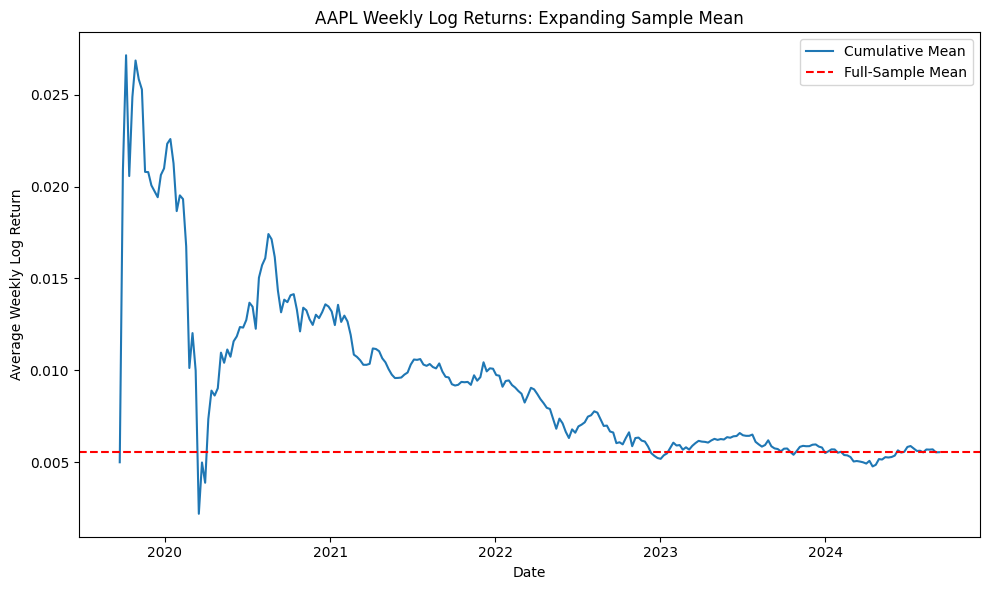

In [ ]:

# Calculate expanding sample mean of weekly log returns
cumulative_mean = weekly_log_returns.expanding().mean()

# Plot the evolution of the sample mean
plt.figure(figsize=(10, 6))

plt.plot(
    cumulative_mean.index,
    cumulative_mean.values,
    label="Cumulative Mean"
)

plt.axhline(
    weekly_log_returns.mean(),
    color="red",
    linestyle="--",
    label="Full-Sample Mean"
)

plt.title("AAPL Weekly Log Returns: Expanding Sample Mean")
plt.xlabel("Date")
plt.ylabel("Average Weekly Log Return")
plt.legend()
plt.tight_layout()
plt.show()
